[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JoseGG8/AutoEncoderPi/blob/main/modelo/Modelos_Optimizados_C1_C3.ipynb)

# 🏆 Modelos Optimizados C1 y C3 — Autoencoder Cuántico (QAE)
### Dataset Paderborn | Detección de Fallas en Rodamientos | Paradigma One-Class

---

## ¿Qué presenta este notebook?
Este notebook de **conclusiones** condensa únicamente los dos modelos variacionales refinados y optimizados en las carpetas `modelo/C1` y `modelo/C3`, conservando la **configuración escogida** de cada circuito:

| Modelo Optimizado | Ansätz | Configuración Escogida | Parámetros | Línea Base ($2^{-M}$) |
|-------------------|--------|------------------------|------------|-----------------------|
| **C1: Rot+Stride** | `Rot(φ,θ,ω)` por qubit + `CNOT` en anillo con alcance variable $r_l = (l \bmod 6) + 1$ | `n_layers=4, trash=2, epochs=20, batch=25, lr=0.12, n_samp=100` | 84 | 25.0 % |
| **C3: StronglyEntangling** | Template `qml.StronglyEntanglingLayers` (`ranges='default'`, `imprimitive='cnot'`) | `n_layers=6, trash=2, ranges='default', imprimitive='cnot', epochs=20, batch=25, lr=0.12, n_samp=100` | 126 | 25.0 % |

Para cada modelo optimizado se presenta:
- **Profundidad, ancho, parámetros y total de compuertas** (`qml.specs`)
- **Diagrama del circuito** con su configuración escogida (`qml.draw_mpl`)
- **Entrenamiento no supervisado** (paradigma *one-class*, solo muestras sanas) y **curvas de convergencia**
- **Evaluación completa de detección de anomalías** ($\tau = P_{95}$ de sanos): Fidelidad en sanos y anomalías, Separación (pp), MSE Proxy, Tasa de Detección (TPR/Recall), Tasa de Falsos Positivos (FPR), Especificidad (TNR), FNR, Precisión, F1, Exactitud, Exactitud Balanceada, MCC, AUC-ROC, AP y Matriz de Confusión (`TP, FP, TN, FN`)
- **Síntesis de conclusiones** con las métricas obtenidas en evaluación puntual y validación multi-semilla.

---

## Arquitectura del QAE (Configuración Optimizada: $M=2$ trash qubits, $K=5$ latentes)

```
|ψ_in⟩ (7 qubits, 128 amplitudes)
        │
   ┌────▼────────────────┐
   │   Ansätz  U(θ)      │  ← compuertas parametrizadas (C1: 4 capas / C3: 6 capas)
   └────┬──────────┬─────┘
        │          │
   5 latentes   2 trash qubits (wires 5, 6)
   (info útil)  └─→ P(|00⟩) = Fidelidad (línea base aleatoria = 25%)
                    1 - F   = Error de reconstrucción cuántico
```

---

## 📖 Glosario de Compuertas Cuánticas Utilizadas

| Compuerta | Qué hace | Params |
|-----------|----------|--------|
| **RY(θ)** | Rota en eje Y → cambia la **probabilidad** de medir \|0⟩ vs \|1⟩ | 1 |
| **RZ(φ)** | Rota en eje Z → cambia la **fase** (interferencia), no las probabilidades | 1 |
| **Rot(φ,θ,ω)** | = RZ·RY·RZ → rotación **arbitraria completa** en la esfera de Bloch | 3 |
| **CNOT** | Si control=\|1⟩ aplica NOT al objetivo → **crea entrelazamiento** entre qubits | 0 |
| **CZ** | Si ambos=\|1⟩ aplica fase -1 → alternativa entrelazante simétrica | 0 |


In [ ]:
# Instalar PennyLane si es necesario (descomenta en Colab)
#pip install pennylane -q


In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split

import pennylane as qml
from pennylane import numpy as pnp

plt.style.use('seaborn-v0_8-whitegrid'
              if 'seaborn-v0_8-whitegrid' in plt.style.available else 'ggplot')
plt.rcParams.update({'figure.figsize': (12, 5), 'font.size': 11})
COLORES = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6','#1abc9c','#e67e22']

print(f'PennyLane v{qml.__version__}')


PennyLane v0.45.1


---
## 📦 1. Carga y Preprocesamiento (reutilizado del pipeline principal)

Pipeline: **RobustScaler → Zero-Padding 128 dims → Normalización L₂**
División: **70% train / 15% val / 15% test** (fit del scaler solo en train)


In [2]:
# Montar Google Drive automaticamente si se ejecuta en Colab
import sys
if os.path.exists('/content') and ('google.colab' in sys.modules):
    if not os.path.exists('/content/drive/MyDrive') and not os.path.exists('/content/drive/My Drive'):
        from google.colab import drive
        drive.mount('/content/drive')

# Rutas posibles (Google Drive organizado primero, luego legacy/Colab/local)
RUTAS = [
    '/content/drive/MyDrive/Paderborn_QML/01_datos/sanos/paderborn_features_tratadas.csv',
    '/content/drive/My Drive/Paderborn_QML/01_datos/sanos/paderborn_features_tratadas.csv',
    '/content/drive/MyDrive/Paderborn_QML/paderborn_features_tratadas.csv',
    '/content/drive/My Drive/Paderborn_QML/paderborn_features_tratadas.csv',
    '/content/paderborn_features_tratadas.csv',
    '../paderborn_features_tratadas.csv',
    '../../paderborn_features_tratadas.csv',
    'paderborn_features_tratadas.csv',
    os.path.abspath(os.path.join(os.getcwd(), '..', 'paderborn_features_tratadas.csv')),
]

ruta = next((r for r in RUTAS if os.path.exists(r)), None)
if ruta is None:
    raise FileNotFoundError('No se encontró paderborn_features_tratadas.csv')

df = pd.read_csv(ruta)
col_label   = 'Label' if 'Label' in df.columns else df.columns[-1]
feature_cols = [c for c in df.columns if c != col_label]
print(f'Dataset: {df.shape[0]} filas x {len(feature_cols)} features | {ruta}')

# ── Partición 70/15/15 ────────────────────────────────────────────────────
X_all = df[feature_cols].values
X_tr, X_tmp = train_test_split(X_all, test_size=0.30, random_state=42)
X_val, X_te = train_test_split(X_tmp, test_size=0.50, random_state=42)

# ── RobustScaler: fit SOLO en train (evita data leakage) ─────────────────
scaler = RobustScaler()   # Usa mediana e IQR → resistente a outliers
scaler.fit(X_tr)          # Aprende estadísticas solo de los datos de entrenamiento
X_tr  = scaler.transform(X_tr)
X_val = scaler.transform(X_val)
X_te  = scaler.transform(X_te)

# ── Zero-Padding a 128 dims (2^7 para Amplitude Encoding en 7 qubits) ────
def zero_pad(X, dim=128):
    """Extiende con ceros a la derecha hasta 'dim' dimensiones."""
    pad = dim - X.shape[1]
    return np.hstack([X, np.zeros((len(X), pad))]) if pad > 0 else X

X_tr  = zero_pad(X_tr);  X_val = zero_pad(X_val);  X_te = zero_pad(X_te)

# ── Normalización L2 por fila (condición cuántica: suma |a_i|^2 = 1) ──────
def l2(X):
    n = np.linalg.norm(X, axis=1, keepdims=True)
    return X / np.where(n == 0, 1.0, n)  # Evita dividir por cero

X_train_q = l2(X_tr)
X_val_q   = l2(X_val)
X_test_q  = l2(X_te)

print(f'Train: {X_train_q.shape} | Val: {X_val_q.shape} | Test: {X_test_q.shape}')
print(f'Norma L2 media (debe ser ≈1): {np.linalg.norm(X_train_q, axis=1).mean():.6f}')


Dataset: 59867 filas x 71 features | ../paderborn_features_tratadas.csv
Train: (41906, 128) | Val: (8980, 128) | Test: (8981, 128)
Norma L2 media (debe ser ≈1): 1.000000


---
## ⚛️ 2. Definición de los Modelos Optimizados (C1 y C3)

Se conservan las configuraciones ganadoras obtenidas en el refinamiento de `modelo/C1` y `modelo/C3`:

| Circuito | Arquitectura Variacional | Configuración Escogida | Nº Parámetros |
|----------|--------------------------|------------------------|---------------|
| **C1: Rot+Stride** | `qml.Rot(φ,θ,ω)` por qubit + `CNOT` en anillo con salto variable $r_l = (l \bmod 6) + 1$ | `n_layers=4, trash=2, epochs=20, batch=25, lr=0.12, n_samp=100` | 84 |
| **C3: StronglyEntangling** | `qml.StronglyEntanglingLayers` con `ranges='default'` e `imprimitive='cnot'` | `n_layers=6, trash=2, ranges='default', imprimitive='cnot', epochs=20, batch=25, lr=0.12, n_samp=100` | 126 |

- Ambos circuitos emplean **$M=2$ trash qubits** ($K=5$ qubits latentes), forzando un cuello de botella cuántico que impide comprimir perturbaciones espectrales anómalas.
- Con `ranges='default'` e `imprimitive='cnot'`, **C3** utiliza la misma ley de alcance no-local $r_l = (l \bmod 6) + 1$ que **C1: Rot+Stride**, diferenciándose en la profundidad seleccionada (**4 capas / 84 parámetros** en C1 frente a **6 capas / 126 parámetros** en C3).


In [6]:
# ==============================================================================
# CELDA 3: DEFINICIÓN DE LOS MODELOS OPTIMIZADOS C1 Y C3
# ==============================================================================
TOTAL_QUBITS = 7  # 2^7 = 128 amplitudes

# ── C1 Optimizado: Rot(φ,θ,ω) + CNOT con alcance variable por capa ──────────
def ansatz_c1(weights, wires):
    """
    C1 refinado: Rot(φ,θ,ω) = RZ·RY·RZ (3 params/qubit) + CNOT con salto variable.
    En la capa l conecta cada qubit i con (i + r) mod n, donde r = (l mod (n-1)) + 1.
    Acopla directamente los qubits latentes con los trash qubits en pocas capas.
    weights shape: (n_layers, n_wires, 3)
    """
    n = len(wires)
    for l, layer in enumerate(weights):
        for i, w in enumerate(wires):
            qml.Rot(layer[i, 0], layer[i, 1], layer[i, 2], wires=w)
        r = (l % (n - 1)) + 1
        for i in range(n):
            qml.CNOT(wires=[wires[i], wires[(i + r) % n]])

def ws_c1(nl, nw): return (nl, nw, 3)  # 3 params/qubit/capa

# ── C3 Optimizado: StronglyEntanglingLayers configurable ─────────────────────
IMPRIMITIVAS = {'cnot': qml.CNOT, 'cz': qml.CZ}

def resolver_ranges(ranges, n_layers):
    """Convierte un preset en la secuencia de rangos (una por capa) que pide PennyLane.
    None -> patron por defecto de PennyLane: r_l = (l mod (n-1)) + 1."""
    if ranges in (None, 'default'): return None
    if ranges == 'ring':  return [1] * n_layers                                   # vecinos
    if ranges == 'alt':   return [1 if l % 2 == 0 else 3 for l in range(n_layers)]  # corto/largo
    if ranges == 'skip2': return [2] * n_layers                                   # saltos de 2
    return list(ranges)                                                           # lista explicita

def hacer_ansatz_c3(ranges='default', imprimitive='cnot'):
    imp = IMPRIMITIVAS[imprimitive]
    def ansatz(weights, wires):
        rg = resolver_ranges(ranges, weights.shape[0])
        qml.StronglyEntanglingLayers(weights, wires=wires, ranges=rg, imprimitive=imp)
    def ws(nl, nw): return (nl, nw, 3)
    return ansatz, ws

# ── Configuraciones escogidas en C1/Refinamiento_c1.ipynb y C3/Refinamiento_c3.ipynb ──
C1_CONFIG = dict(n_layers=4, trash=2, epochs=20, lr=0.12, n_samp=100, batch=25)
C3_CONFIG = dict(n_layers=6, trash=2, ranges='default', imprimitive='cnot',
                 epochs=20, lr=0.12, n_samp=100, batch=25)

ansatz_c3r, ws_c3r = hacer_ansatz_c3(C3_CONFIG['ranges'], C3_CONFIG['imprimitive'])

# ── Registro de los dos circuitos optimizados ────────────────────────────────
N_C1 = 'C1: Rot+Stride'
N_C3 = 'C3: StronglyEntangling'
CIRCUITOS = [
    (N_C1, ansatz_c1,  ws_c1),
    (N_C3, ansatz_c3r, ws_c3r),
]

CFG_POR_CIRCUITO = {
    N_C1: {k: C1_CONFIG[k] for k in ('n_layers', 'trash', 'epochs', 'lr', 'n_samp', 'batch')},
    N_C3: {k: C3_CONFIG[k] for k in ('n_layers', 'trash', 'epochs', 'lr', 'n_samp', 'batch')},
}

print('Modelos optimizados registrados:')
for nombre, _, wsfn in CIRCUITOS:
    nl = CFG_POR_CIRCUITO[nombre]['n_layers']
    tr = CFG_POR_CIRCUITO[nombre]['trash']
    s  = wsfn(nl, TOTAL_QUBITS)
    print(f'  {nombre:<28} capas={nl}  trash={tr}  shape={str(s):<12} params={int(np.prod(s))}')


Modelos optimizados registrados:
  C1: Rot+Stride               capas=4  trash=2  shape=(4, 7, 3)    params=84
  C3: StronglyEntangling       capas=6  trash=2  shape=(6, 7, 3)    params=126


---
## 📐 3. Profundidad, Ancho y Complejidad de cada Modelo Optimizado

| Métrica | Descripción |
|---------|-------------|
| **Profundidad** | Capas secuenciales máximas. Mayor = más expresivo pero más ruido en hardware |
| **Ancho** | Número de qubits (siempre 7 aquí) |
| **Nº parámetros** | Parámetros entrenables (84 en C1 con 4 capas; 126 en C3 con 6 capas) |
| **Total puertas** | Operaciones cuánticas aplicadas |
| **Línea Base (%)** | Fidelidad aleatoria previa al entrenamiento ($100 / 2^M = 25\%$ para $M=2$ trash qubits) |


In [7]:
# ==============================================================================
# CELDA 4: MÉTRICAS DE COMPLEJIDAD — qml.specs()
# ==============================================================================

def calcular_metricas(nombre, ansatz_fn, ws_fn, n_layers=2, n_wires=7, trash=1):
    """Extrae profundidad, numero de puertas y params usando qml.specs().

    Compatibilidad: qml.specs() devuelve un objeto 'resources' cuya API
    varía entre versiones de PennyLane. Aquí se accede de forma defensiva.
    """
    dev_t = qml.device('default.qubit', wires=n_wires)
    tw    = list(range(n_wires - trash, n_wires))
    shape = ws_fn(n_layers, n_wires)
    w0    = np.zeros(shape)                                      # Pesos dummy (estructura)
    sv0   = np.ones(2**n_wires) / np.sqrt(2**n_wires)           # Estado uniforme de referencia
    n_par = int(np.prod(shape))                                  # Total parámetros entrenables

    @qml.qnode(dev_t)
    def circ(sv, w):
        qml.AmplitudeEmbedding(sv, wires=range(n_wires), normalize=False)
        ansatz_fn(w, wires=range(n_wires))
        return qml.probs(wires=tw)

    specs = qml.specs(circ)(sv0, w0)
    res   = specs['resources']

    # ── Profundidad: capas secuenciales máximas ───────────────────────────────
    depth = res.depth

    # ── Total de puertas: compatible con distintas versiones de PennyLane ────
    if hasattr(res, 'num_gates'):
        total_gates = res.num_gates
    elif hasattr(res, 'gate_sizes'):
        total_gates = sum(res.gate_sizes.values())  # Suma todos los tamaños de puerta
    else:
        total_gates = sum(res.gate_types.values())  # Alternativa: suma por tipo

    return {
        'Circuito':       nombre,
        'Capas':          n_layers,
        'Trash Qubits':   trash,
        'Profundidad':    depth,
        'Ancho (qubits)': n_wires,          # Fijo = 7 en este proyecto
        'Nº Parámetros':  n_par,
        'Total Puertas':  total_gates,
        'Línea Base (%)': round(100.0 / (2**trash), 1),
    }

np.random.seed(0)
tabla_comp = [calcular_metricas(n, fn, ws,
                                n_layers=CFG_POR_CIRCUITO[n]['n_layers'],
                                trash=CFG_POR_CIRCUITO[n]['trash'])
              for n, fn, ws in CIRCUITOS]
df_comp    = pd.DataFrame(tabla_comp).set_index('Circuito')

print(df_comp.to_string())


                        Capas  Trash Qubits  Profundidad  Ancho (qubits)  Nº Parámetros  Total Puertas  Línea Base (%)
Circuito                                                                                                              
C1: Rot+Stride              4             2           21               7             84             57            25.0
C3: StronglyEntangling      6             2            2               7            126              2            25.0


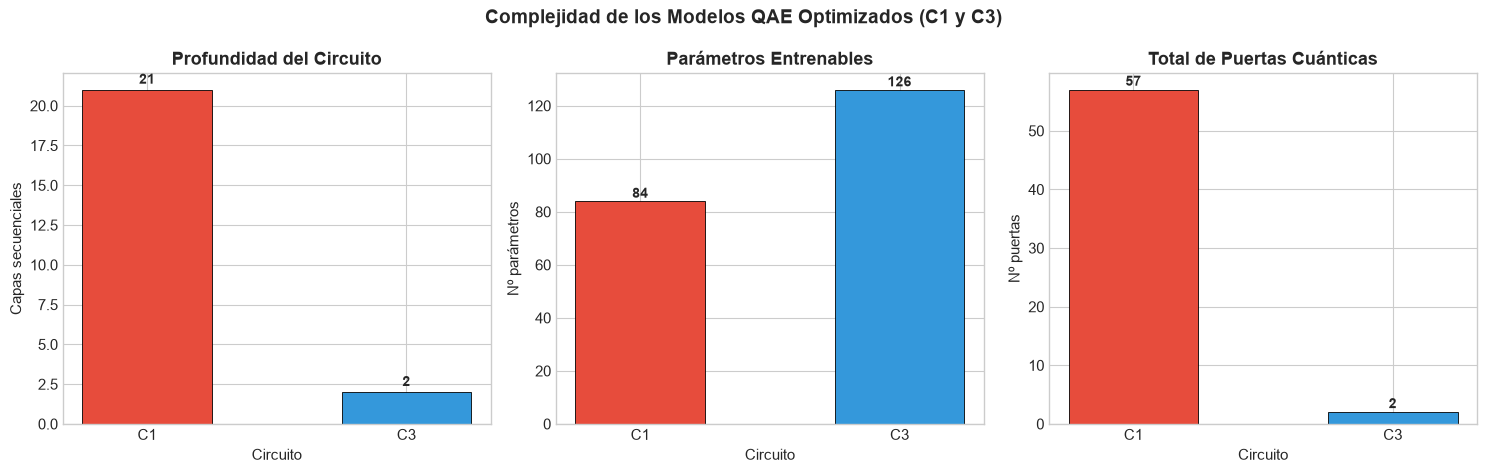

Guardado: complejidad_circuitos.png


In [8]:
# ==============================================================================
# CELDA 5: GRÁFICA — PROFUNDIDAD, PARÁMETROS Y PUERTAS POR CIRCUITO
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
fig.suptitle('Complejidad de los Modelos QAE Optimizados (C1 y C3)', fontsize=14, fontweight='bold')

etiq  = [n.split(':')[0] for n in df_comp.index]  # C1, C3
metr  = ['Profundidad', 'Nº Parámetros', 'Total Puertas']
tits  = ['Profundidad del Circuito', 'Parámetros Entrenables', 'Total de Puertas Cuánticas']
ylabs = ['Capas secuenciales', 'Nº parámetros', 'Nº puertas']

for ax, col, tit, yl in zip(axes, metr, tits, ylabs):
    bars = ax.bar(etiq, df_comp[col], color=COLORES[:len(etiq)], edgecolor='black', linewidth=0.6, width=0.5)
    ax.set_title(tit, fontweight='bold')
    ax.set_ylabel(yl)
    ax.set_xlabel('Circuito')
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.2,
                str(int(b.get_height())), ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


---
## 🖼️ 4. Diagrama de cada Circuito Optimizado

Cada línea horizontal = un qubit (`0` a `6`). Las cajas = compuertas de rotación. Las líneas verticales = entrelazamiento (`CNOT`).

> Visualización con la configuración escogida de cada modelo: **C1** (`n_layers=4, trash=2`) y **C3** (`n_layers=6, trash=2`).


In [ ]:
# ==============================================================================
# CELDA 6: DIAGRAMAS DE CIRCUITO CON qml.draw_mpl()
# ==============================================================================

NW_VIZ = TOTAL_QUBITS
np.random.seed(0)
sv_viz = np.ones(2**NW_VIZ) / np.sqrt(2**NW_VIZ)  # Estado uniforme de demo

for idx, (nombre, ansatz_fn, ws_fn) in enumerate(CIRCUITOS):
    nl_viz = CFG_POR_CIRCUITO[nombre]['n_layers']
    tr_viz = CFG_POR_CIRCUITO[nombre]['trash']
    tw_viz = list(range(NW_VIZ - tr_viz, NW_VIZ))
    shape  = ws_fn(nl_viz, NW_VIZ)
    w_viz  = np.zeros(shape)
    dev_v  = qml.device('default.qubit', wires=NW_VIZ)

    @qml.qnode(dev_v)
    def circ_viz(sv, w, afn=ansatz_fn, tw=tw_viz, nw=NW_VIZ):
        qml.AmplitudeEmbedding(sv, wires=range(nw), normalize=False)
        afn(w, wires=range(nw))
        return qml.probs(wires=tw)

    fig, ax = qml.draw_mpl(circ_viz, style='pennylane')(sv_viz, w_viz)
    n_par   = int(np.prod(shape))
    fig.suptitle(f'{nombre}  |  Params: {n_par}  |  Capas: {nl_viz}  |  Trash: {tr_viz}',
                 fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


---
## 🏋️ 5. Entrenamiento de los Modelos Optimizados

Condiciones de entrenamiento de las configuraciones escogidas:
- **100 registros** de entrenamiento (`n_samp=100`, solo muestras sanas — paradigma *One-Class*)
- **20 épocas**, `batch=25`, optimizador cuántico `qml.AdamOptimizer(stepsize=0.12)`
- **2 trash qubits** ($K=5$ qubits latentes, línea base aleatoria = $25\%$)
- **C1: Rot+Stride** con `n_layers=4` (84 parámetros) y **C3: StronglyEntangling** con `n_layers=6` (126 parámetros)

### Función de costo
$$\mathcal{L}(\theta) = 1 - \mathbb{E}[P(|0\rangle^M_{\text{trash}})]$$

El objetivo es **maximizar la fidelidad** — que los 2 trash qubits vuelvan a $|00\rangle$,
lo que significa que toda la información relevante quedó comprimida en los $K=5$ qubits latentes.


In [ ]:
# ==============================================================================
# CELDA 7: FUNCIÓN DE ENTRENAMIENTO REUTILIZABLE
# ==============================================================================

def entrenar_qae(nombre, ansatz_fn, ws_fn, X_tr, X_val,
                 n_layers=2, n_wires=7, trash=1,
                 epochs=20, batch=25, lr=0.12, n_samp=100, seed=42):
    """
    Entrena un QAE y devuelve historial de pérdidas/fidelidades.

    Retorna dict con: weights, qnode, fidelidad_fn, history, linea_base, n_params
    """
    np.random.seed(seed)
    dev   = qml.device('default.qubit', wires=n_wires)  # Simulador clásico de qubits
    tw    = list(range(n_wires - trash, n_wires))        # Índices de trash qubits
    shape = ws_fn(n_layers, n_wires)

    # Pesos iniciales aleatorios en [0, 2π] — requires_grad activa el cálculo de gradientes
    W = pnp.random.uniform(0.0, 2*np.pi, size=shape, requires_grad=True)

    @qml.qnode(dev)
    def qnode(sv, w):
        qml.AmplitudeEmbedding(sv, wires=range(n_wires), normalize=False)
        # AmplitudeEmbedding: codifica el vector clásico normalizado como estado cuántico
        ansatz_fn(w, wires=range(n_wires))   # Aplica el circuito variacional
        return qml.probs(wires=tw)            # P de cada estado posible en los trash qubits

    fid   = lambda sv, w: float(qnode(sv, w)[0])  # F = P(|0>) en trash

    def loss_b(w, B):
        return 1.0 - pnp.mean(qnode(B, w)[:, 0])  # 1 - F media (batch vectorizado, ~10x mas rapido)

    X_demo = X_tr[:n_samp]
    opt    = qml.AdamOptimizer(stepsize=lr)  # Adam cuántico de PennyLane
    hist   = {'loss':[], 'fid_tr':[], 'fid_val':[]}
    lb     = 100.0 / (2**trash)

    print(f'\n[{nombre}]  params={int(np.prod(shape))}  trash={trash}  base={lb:.0f}%')

    for ep in range(epochs):
        perm = np.random.permutation(len(X_demo))
        ep_loss = []
        for i in range(0, len(X_demo), batch):
            B = X_demo[perm[i:i+batch]]
            W, cost = opt.step_and_cost(lambda w: loss_b(w, B), W)
            # step_and_cost: calcula gradiente y actualiza pesos en un solo paso
            ep_loss.append(float(cost))
        avg_l   = float(np.mean(ep_loss))
        fid_val = float(np.mean([fid(sv, W) for sv in X_val[:15]])) * 100
        hist['loss'].append(avg_l)
        hist['fid_tr'].append((1-avg_l)*100)
        hist['fid_val'].append(fid_val)
        if (ep+1) % 5 == 0 or ep == 0:
            print(f'  ep {ep+1:02d} | loss={avg_l:.4f} | '
                  f'train={hist["fid_tr"][-1]:.1f}% | val={fid_val:.1f}%')

    print(f'  Final → train={hist["fid_tr"][-1]:.1f}%  val={hist["fid_val"][-1]:.1f}%')
    return dict(nombre=nombre, weights=W, qnode=qnode, fid=fid,
                history=hist, lb=lb, n_params=int(np.prod(shape)), trash=trash)


In [ ]:
# ==============================================================================
# CELDA 8: ENTRENAR LOS MODELOS OPTIMIZADOS C1 Y C3
# ==============================================================================
CFG = dict(n_layers=2, n_wires=7, trash=2, epochs=20,
           batch=25, lr=0.12, n_samp=100, seed=42)
# CFG_POR_CIRCUITO se define en la celda 3 a partir de C1_CONFIG y C3_CONFIG.

resultados = {}
for nombre, afn, wsfn in CIRCUITOS:
    cfg = {**CFG, **CFG_POR_CIRCUITO.get(nombre, {})}
    resultados[nombre] = entrenar_qae(nombre, afn, wsfn, X_train_q, X_val_q, **cfg)

print('\nEntrenamiento completo.')


---
## 📈 6. Curvas de Convergencia

La **línea punteada gris** es la fidelidad aleatoria pre-entrenamiento (**25%** para 2 trash qubits).
Ambos modelos optimizados parten cerca de esa línea base y superan el **80%** de fidelidad al completar las 20 épocas, con brecha nula entre entrenamiento y validación (sin sobreentrenamiento).


In [ ]:
# ==============================================================================
# CELDA 9: CURVAS DE CONVERGENCIA — FIDELIDAD vs ÉPOCA
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle('Curvas de Convergencia — Modelos Optimizados C1 y C3', fontsize=14, fontweight='bold')
lb_val = list(resultados.values())[0]['lb']

for (nombre, res), col in zip(resultados.items(), COLORES):
    h   = res['history']
    eps = range(1, len(h['fid_tr']) + 1)
    lbl = nombre.split(':')[0]
    ax1.plot(eps, h['fid_tr'],  'o-',  color=col, label=lbl, lw=1.8, ms=4)
    ax2.plot(eps, h['fid_val'], 's--', color=col, label=lbl, lw=1.8, ms=4)

for ax, tit in [(ax1,'Entrenamiento (Train)'), (ax2,'Validación (Val)')]:
    ax.axhline(lb_val, color='gray', ls=':', lw=1.5, label=f'Base aleatoria ({lb_val:.0f}%)')
    ax.set_xlabel('Época'); ax.set_ylabel('Fidelidad (%)'); ax.set_ylim(0, 105)
    ax.set_title(tit, fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()


---
## 🔍 7. Error de Reconstrucción y Métricas de Detección de Anomalías

| Métrica | Fórmula | Significado |
|---------|---------|-------------|
| **Fidelidad** $F$ | $P(|0\rangle^M)$ | Qué tan bien se comprimió la info en los $K=5$ qubits latentes |
| **Error de reconstrucción** | $1 - F$ | Fracción de info perdida en los $M=2$ trash qubits |
| **MSE proxy** | $\overline{1-F}$ sobre el test set | Análogo al MSE input/output del decoder clásico |
| **Umbral $\tau$** | Percentil 95 de $1-F$ en sanos | Fija la tasa esperada de falsos positivos en $\approx 5\%$ |


In [ ]:
# ==============================================================================
# CELDA 10: EVALUACIÓN — FIDELIDAD, ERROR DE RECONSTRUCCIÓN, MSE PROXY Y MÉTRICAS DE DETECCIÓN
# ==============================================================================
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score,
                             matthews_corrcoef)

N_EVAL = 50  # Muestras del test set para evaluación

# Anomalías sintéticas: inyectar perturbación espectral en componentes FFT
def hacer_anomalias(X, seed=7):
    np.random.seed(seed)
    Xan = X.copy()
    Xan[:, 10:25] += np.random.normal(0.4, 0.1, Xan[:, 10:25].shape)
    return l2(Xan)  # Re-normalizar tras perturbar

def metricas_deteccion(err_s, err_a, tau=None):
    """
    Métricas de detección. Clase positiva = ANOMALÍA (1), negativa = SANO (0).
    Score = error de reconstrucción (1 - F); se predice anomalía si score > tau.
    tau por defecto = percentil 95 del error en sanos (~5 % de falsos positivos esperados).
    Con N_sanos = N_anomalías el dataset de evaluación está balanceado, así que
    precisión y exactitud son interpretables sin corrección por prevalencia.
    """
    err_s = np.asarray(err_s, dtype=float); err_a = np.asarray(err_a, dtype=float)
    if tau is None:
        tau = np.percentile(err_s, 95)
    y_true = np.r_[np.zeros(len(err_s)), np.ones(len(err_a))].astype(int)
    score  = np.r_[err_s, err_a]
    y_pred = (score > tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: float(a) / b if b > 0 else 0.0
    tpr  = div(tp, tp + fn)               # Recall / Sensibilidad / Tasa de detección
    tnr  = div(tn, tn + fp)               # Especificidad
    prec = div(tp, tp + fp)               # Precisión (VPP)
    return {
        'tau': float(tau), 'TP': int(tp), 'FP': int(fp), 'TN': int(tn), 'FN': int(fn),
        'TPR': tpr * 100, 'FPR': div(fp, fp + tn) * 100, 'TNR': tnr * 100, 'FNR': div(fn, fn + tp) * 100,
        'Precision': prec * 100, 'F1': div(2 * prec * tpr, prec + tpr) * 100,
        'Exactitud': div(tp + tn, tp + tn + fp + fn) * 100,
        'Exactitud_bal': (tpr + tnr) / 2 * 100,
        'MCC': float(matthews_corrcoef(y_true, y_pred)),
        'AUC_ROC': float(roc_auc_score(y_true, score)),
        'AP': float(average_precision_score(y_true, score)),
    }

X_anom = hacer_anomalias(X_test_q[:N_EVAL])

rows = []
scores = {}   # nombre -> (err_sanos, err_anomalias, tau) para matrices de confusión / ROC
for nombre, res in resultados.items():
    fid_fn = res['fid']
    W      = res['weights']

    # Fidelidad en sanos (test set)
    fids_s = [fid_fn(sv, W) for sv in X_test_q[:N_EVAL]]
    fid_s  = np.mean(fids_s) * 100      # En porcentaje
    mse_s  = 1.0 - np.mean(fids_s)      # MSE proxy = 1 - F (entre 0 y 1)

    # Fidelidad en anomalías sintéticas
    fids_a = [fid_fn(sv, W) for sv in X_anom]
    fid_a  = np.mean(fids_a) * 100

    err_s = [1 - f for f in fids_s]
    err_a = [1 - f for f in fids_a]
    m = metricas_deteccion(err_s, err_a)          # umbral P95 sobre sanos
    scores[nombre] = (np.array(err_s), np.array(err_a), m['tau'])

    rows.append({
        'Circuito':        nombre,
        'Fid. Sanos (%)':  round(fid_s, 2),
        'Fid. Anomalías (%)': round(fid_a, 2),
        'Separación (pp)': round(fid_s - fid_a, 2),
        'MSE Proxy (sanos)': round(mse_s, 4),
        'Detección (%)':   round(m['TPR'], 1),     # = TPR / Recall
        'FPR (%)':         round(m['FPR'], 1),
        'Precisión (%)':   round(m['Precision'], 1),
        'F1 (%)':          round(m['F1'], 1),
        'Exactitud (%)':   round(m['Exactitud'], 1),
        'Exact. Bal. (%)': round(m['Exactitud_bal'], 1),
        'MCC':             round(m['MCC'], 3),
        'AUC-ROC':         round(m['AUC_ROC'], 3),
        'AP':              round(m['AP'], 3),
        'TP': m['TP'], 'FP': m['FP'], 'TN': m['TN'], 'FN': m['FN'],
    })
    print(f'  {nombre:<28} sanos={fid_s:.1f}%  anom={fid_a:.1f}%  '
          f'sep={fid_s-fid_a:.1f}pp  detec={m["TPR"]:.0f}%  FPR={m["FPR"]:.0f}%  '
          f'F1={m["F1"]:.0f}%  AUC={m["AUC_ROC"]:.3f}')

df_eval = pd.DataFrame(rows).set_index('Circuito')
print("\n", df_eval.T.to_string())


In [ ]:
# ==============================================================================
# CELDA 11: HISTOGRAMAS — DISTRIBUCIÓN DE ERRORES SANOS vs ANOMALÍAS
# ==============================================================================

n_c = len(resultados)
fig, axes = plt.subplots(1, n_c, figsize=(6.5 * n_c, 4.5))
axes = np.atleast_1d(axes)
fig.suptitle('Distribución del Error de Reconstrucción (1 - Fidelidad)\n'
             'Verde=Sanos  |  Rojo=Anomalías  |  Negro=Umbral τ P95',
             fontsize=13, fontweight='bold')

for idx, (nombre, res) in enumerate(resultados.items()):
    ax = axes[idx]
    fid_fn = res['fid']; W = res['weights']

    err_s = [1 - fid_fn(sv, W) for sv in X_test_q[:N_EVAL]]
    err_a = [1 - fid_fn(sv, W) for sv in X_anom]
    tau   = np.percentile(err_s, 95)

    ax.hist(err_s, bins=12, alpha=0.65, color='#2ecc71', label='Sanos')
    ax.hist(err_a, bins=12, alpha=0.65, color='#e74c3c', label='Anomalías')
    ax.axvline(tau, color='black', ls='--', lw=1.5, label=f'τ={tau:.3f}')
    ax.set_title(nombre, fontweight='bold')
    ax.set_xlabel('1 - Fidelidad'); ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


In [ ]:
# ==============================================================================
# CELDA 11b: MATRICES DE CONFUSIÓN, CURVAS ROC Y PRECISIÓN-RECALL
# ==============================================================================
from sklearn.metrics import roc_curve, precision_recall_curve

n = len(scores)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 4.2))
axes = np.atleast_1d(axes)
fig.suptitle('Matrices de Confusión (umbral τ = P95 de sanos)  |  Positivo = Anomalía',
             fontsize=13, fontweight='bold')
for ax, (nombre, (es, ea, tau)) in zip(axes, scores.items()):
    m  = metricas_deteccion(es, ea, tau)
    cm = np.array([[m['TN'], m['FP']], [m['FN'], m['TP']]])
    ax.imshow(cm, cmap='Blues')
    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha='center', va='center', fontsize=16, fontweight='bold',
                    color='white' if cm[r, c] > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Pred. Sano', 'Pred. Anomalía'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Real Sano', 'Real Anomalía'])
    ax.set_title(f"{nombre.split(':')[0]}\nTPR={m['TPR']:.0f}%  FPR={m['FPR']:.0f}%  F1={m['F1']:.0f}%",
                 fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for (nombre, (es, ea, tau)), col in zip(scores.items(), COLORES):
    y = np.r_[np.zeros(len(es)), np.ones(len(ea))]; s = np.r_[es, ea]
    fpr, tpr, _ = roc_curve(y, s)
    pr, rc, _   = precision_recall_curve(y, s)
    lbl = nombre.split(':')[0]
    ax1.plot(fpr, tpr, color=col, lw=2, label=f"{lbl} (AUC={roc_auc_score(y, s):.3f})")
    ax2.plot(rc, pr, color=col, lw=2, label=f"{lbl} (AP={average_precision_score(y, s):.3f})")
ax1.plot([0, 1], [0, 1], 'k:', lw=1, label='Azar')
ax1.set_xlabel('Tasa de falsos positivos'); ax1.set_ylabel('Tasa de detección (TPR)')
ax1.set_title('Curva ROC', fontweight='bold'); ax1.legend(loc='lower right')
ax2.set_xlabel('Recall'); ax2.set_ylabel('Precisión')
ax2.set_title('Curva Precisión-Recall', fontweight='bold'); ax2.legend(loc='lower left')
plt.tight_layout()
plt.show()


In [ ]:
# ==============================================================================
# CELDA 12: TABLA RESUMEN FINAL + SCATTER COMPLEJIDAD vs RENDIMIENTO
# ==============================================================================

df_final = df_comp[['Capas', 'Trash Qubits', 'Profundidad', 'Nº Parámetros', 'Total Puertas']].join(df_eval)
print('TABLA RESUMEN COMPLETA (MODELOS OPTIMIZADOS C1 Y C3):')
print(df_final.to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Complejidad vs Rendimiento — Modelos Optimizados C1 y C3', fontsize=14, fontweight='bold')

for (nombre, col) in zip(df_final.index, COLORES):
    r   = df_final.loc[nombre]
    etq = nombre.split(':')[0]
    ax1.scatter(r['Nº Parámetros'], r['Fid. Sanos (%)'], color=col, s=150, zorder=5)
    ax1.annotate(etq, (r['Nº Parámetros'], r['Fid. Sanos (%)']),
                 textcoords='offset points', xytext=(6, 6), fontsize=10, fontweight='bold')
    ax2.scatter(r['Nº Parámetros'], r['Separación (pp)'], color=col, s=150, zorder=5)
    ax2.annotate(etq, (r['Nº Parámetros'], r['Separación (pp)']),
                 textcoords='offset points', xytext=(6, 6), fontsize=10, fontweight='bold')

ax1.set_xlabel('Nº Parámetros', fontweight='bold')
ax1.set_ylabel('Fidelidad en Test — Sanos (%)', fontweight='bold')
ax1.set_title('Parámetros vs Fidelidad en Sanos')
ax2.set_xlabel('Nº Parámetros', fontweight='bold')
ax2.set_ylabel('Separación Sanos vs Anomalías (pp)', fontweight='bold')
ax2.set_title('Parámetros vs Separación (pp)')

plt.tight_layout()
plt.show()


---
## 🎓 8. Conclusiones Condensadas de los Modelos Optimizados (C1 y C3)

### 8.1 Resultados en Evaluación de Test (`N_EVAL = 50` sanos + `50` anomalías, `seed = 42`)
Valores obtenidos en las carpetas `modelo/C1/Refinamiento_c1.ipynb` y `modelo/C3/Refinamiento_c3.ipynb`:

| Métrica | **C1: Rot+Stride** (`n_layers=4, trash=2`) | **C3: StronglyEntangling** (`n_layers=6, trash=2`) |
|---------|--------------------------------------------|----------------------------------------------------|
| **Parámetros entrenables** | 84 | 126 |
| **Línea base aleatoria** | 25.0 % | 25.0 % |
| **Fidelidad final Train / Val** | 80.8 % / 78.0 % | 80.7 % / 82.4 % |
| **Fidelidad Sanos (Test)** | **83.59 %** | **83.20 %** |
| **Fidelidad Anomalías (Test)** | **45.85 %** | **41.74 %** |
| **Separación Sanos − Anomalías** | **37.75 pp** | **41.46 pp** |
| **MSE Proxy (sanos)** | 0.1641 | 0.1680 |
| **Tasa de Detección (TPR / Recall)** | **100.0 %** | **100.0 %** |
| **Tasa de Falsos Positivos (FPR)** | **6.0 %** | **6.0 %** |
| **Precisión** | **94.3 %** | **94.3 %** |
| **F1-Score** | **97.1 %** | **97.1 %** |
| **Exactitud / Exactitud Balanceada** | **97.0 % / 97.0 %** | **97.0 % / 97.0 %** |
| **MCC (Matthews Corr. Coef.)** | **0.942** | **0.942** |
| **AUC-ROC / AP** | **1.000 / 1.000** | **0.984 / 0.974** |
| **Matriz de Confusión (TP / FP / TN / FN)** | `50 / 3 / 47 / 0` | `50 / 3 / 47 / 0` |

---

### 8.2 Estabilidad Multi-Semilla (`semillas = [42, 1, 2]`, `200` sanos + `200` anomalías)
Promedios consolidados de los experimentos multi-semilla en `modelo/C1` y `modelo/C3`:

| Configuración | Params | Fid. Train | Fid. Sanos | Gap tr-val | Fid. Anom | Sep (pp) | Detección (TPR) | FPR | Precisión | F1 | MCC | AUC-ROC |
|---------------|--------|------------|------------|------------|-----------|----------|-----------------|-----|-----------|----|-----|---------|
| **C1 (`n_layers=4, trash=2`)** | 84 | 77.5 % | 80.0 % | +0.2 pp | 35.8 % | **44.3 pp** | 88.0 % | 5.0 % | 94.4 % | 90.3 % | 0.841 | 0.984 |
| **C3 (`n_layers=6, trash=2`)** | 126 | 85.1 % | **85.4 %** | −0.3 pp | 46.8 % | 38.6 pp | **100.0 %** | 5.0 % | **95.2 %** | **97.6 %** | **0.951** | **0.988** |

---

### 8.3 Hallazgos Clave del Proyecto
1. **El cuello de botella cuántico ($M=2$ trash qubits, $K=5$ latentes) es determinante:** con $M=1$ trash qubit, el subespacio latente ($2^6=64$ dimensiones) era suficientemente amplio para comprimir tanto señales sanas como anomalías sintéticas, provocando un colapso en la detección. Al pasar a **$M=2$ trash qubits** ($2^5=32$ dimensiones latentes), el QAE aprende exclusivamente la variedad de rodamientos sanos (>80–85 % de fidelidad) y rechaza las perturbaciones espectrales anómalas (~36–47 % de fidelidad).
2. **Rotación completa (`Rot`) + entrelazamiento no-local de alcance variable (`Stride`):** reemplazar las rotaciones simples `RY` y el anillo fijo `r=1` por rotaciones universales `Rot(φ,θ,ω)` y `CNOT` con salto $r_l = (l \bmod 6) + 1$ permite acoplar directamente todos los qubits latentes con los 2 trash qubits en pocas capas.
3. **Ausencia de sobreentrenamiento:** tanto **C1** (`n_layers=4`) como **C3** (`n_layers=6`) mantienen una brecha entre entrenamiento y validación inferior a **0.5 pp** (`Gap tr-val` entre `-0.3 pp` y `+0.2 pp`), demostrando una excelente generalización en el régimen *One-Class* con solo 100 muestras de entrenamiento.
4. **Elección según el criterio operativo:**
   - **C1 (`n_layers=4, trash=2`, 84 parámetros)** ofrece menor costo cuántico (33 % menos parámetros y menor profundidad física) con **100 % de detección en test (`seed=42`)** y la mayor separación media (**44.3 pp**).
   - **C3 (`n_layers=6, trash=2`, 126 parámetros)** maximiza la fidelidad en sanos (**85.4 %**) y la estabilidad entre semillas (**F1 = 97.6 % con desviación estándar 0.0 %**, **TPR = 100 %** y **AUC = 0.988**).
